
# **project title:**

# Decoding Child Malnutrition: Wasting Trends, Wealth and Mother's Education


**Project Goal:**

Analyze wasting prevalence and trends among children under 5 across 164 countries using data preprocessing, EDA, visualization, and statistical modeling to generate actionable insights for public health.

**PROJECT OBJECTIVES:**

1. To analyze global trends in wasting among children under 5 across countries and years.

2. To examine how household wealth influences child wasting rates.
3. To study the relationship between mother's education level and child wasting.
4. To compare wasting across urban/rural areas, sex and age groups.
5. To extract actionable public-health insights using Python-based Exploratory Data Analysis (EDA) on 57,967 records (WHO data).







**METHODOLOGY**

1. Data Understanding: Dataset loaded using pandas.read_excel() and understood using info(), describe(), shape and head().
2. Data Cleaning: Missing values, duplicates, data types and outliers (IQR method) were checked and handled.
3. Data Visualization: Visual analysis done using matplotlib.pyplot and seaborn with histplot(), boxplot(), barplot() and heatmap() for correlation.
4. Exploratory Data Analysis (EDA): Pattern analysis done using groupby(), value_counts() and corr().



# **1.Importing Libraries**

The following Python libraries are used in this project for data manipulation, numerical calculations, and data visualization.


*   Pandas: Used to load, clean, organize, and analyze the dataset.


*   NumPy: Used for numerical operations and calculations.
*   Matplotlib: Used to create charts and graphs for data visualization.


*   Seaborn: Used to create statistical visualizations and explore relationships between variables.


*   Plotly: Used to create interactive and visually appealing charts that allow users to zoom, hover, and explore data dynamically.










In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

## Dataset Information

| Attribute | Value |
|---|---|
| Source | World Health Organization (WHO) |
| Indicator | Wasting in children (under 5) |
| Records | 57,967 |
| Total Columns | 22 |
| Countries | 164 |
| Years Covered | 1983 to 2024 |
| Target Variable | Wasting rate (RATE_PER_100_N, % of children) |
| Data Types | Numerical and Categorical |
| Analysis Type | Exploratory Data Analysis (EDA) |

**Dataset Link:** https://data.who.int/indicators/i/6461116/FC5231F




# **2.Data Loading**

The dataset is loaded into Python using Pandas. The data is read from the RELAY_WHS (6).csv file and stored in a DataFrame named df for further analysis.



In [ ]:
df=pd.read_csv("/content/RELAY_WHS (6).csv")
df.head()

,IND_ID,IND_CODE,IND_UUID,IND_PER_CODE,DIM_TIME,DIM_TIME_TYPE,DIM_GEO_CODE_M49,DIM_GEO_CODE_TYPE,DIM_PUBLISH_STATE_CODE,IND_NAME,...,DIM_HOUSEHOLDWEALTH,DIM_POP_EDU_LEVELMOTHER,DIM_POP_WEALTH_DECILE,DIM_POP_WEALTH_QUINTILE,DIM_SEX,DIM_WEALTHTERCILE,DIM_AGE,RATE_PER_100_N,RATE_PER_100_NL,RATE_PER_100_NU
0,FC5231FNUTRITION_WH_2,NUTRITION_WH_2,FC5231F,NUTRITION_WH_2,2011,YEAR,120,COUNTRY,PUBLISHED,Wasting in children (under 5),...,NaN,NaN,NaN,WQ1,NaN,NaN,NaN,10.5,8.4,13.2
1,FC5231FNUTRITION_WH_2,NUTRITION_WH_2,FC5231F,NUTRITION_WH_2,2014,YEAR,748,COUNTRY,PUBLISHED,Wasting in children (under 5),...,NaN,NaN,NaN,WQ1,NaN,NaN,NaN,2.1,1.0,4.4
2,FC5231FNUTRITION_WH_2,NUTRITION_WH_2,FC5231F,NUTRITION_WH_2,2011,YEAR,226,COUNTRY,PUBLISHED,Wasting in children (under 5),...,NaN,NaN,NaN,WQ1,NaN,NaN,NaN,5.3,NaN,NaN
3,FC5231FNUTRITION_WH_2,NUTRITION_WH_2,FC5231F,NUTRITION_WH_2,2016,YEAR,764,COUNTRY,PUBLISHED,Wasting in children (under 5),...,NaN,NaN,NaN,WQ1,NaN,NaN,NaN,6.1,4.1,8.9
4,FC5231FNUTRITION_WH_2,NUTRITION_WH_2,FC5231F,NUTRITION_WH_2,2011,YEAR,288,COUNTRY,PUBLISHED,Wasting in children (under 5),...,NaN,NaN,NaN,WQ1,NaN,NaN,NaN,7.6,6.5,9.0


# **3.Initial Data Overview**

The initial data overview helps us understand the structure, size, column names, and data types of the dataset before starting preprocessing and analysis.

In [ ]:
# First five rows
df.head()

,IND_ID,IND_CODE,IND_UUID,IND_PER_CODE,DIM_TIME,DIM_TIME_TYPE,DIM_GEO_CODE_M49,DIM_GEO_CODE_TYPE,DIM_PUBLISH_STATE_CODE,IND_NAME,...,DIM_HOUSEHOLDWEALTH,DIM_POP_EDU_LEVELMOTHER,DIM_POP_WEALTH_DECILE,DIM_POP_WEALTH_QUINTILE,DIM_SEX,DIM_WEALTHTERCILE,DIM_AGE,RATE_PER_100_N,RATE_PER_100_NL,RATE_PER_100_NU
0,FC5231FNUTRITION_WH_2,NUTRITION_WH_2,FC5231F,NUTRITION_WH_2,2011,YEAR,120,COUNTRY,PUBLISHED,Wasting in children (under 5),...,NaN,NaN,NaN,WQ1,NaN,NaN,NaN,10.5,8.4,13.2
1,FC5231FNUTRITION_WH_2,NUTRITION_WH_2,FC5231F,NUTRITION_WH_2,2014,YEAR,748,COUNTRY,PUBLISHED,Wasting in children (under 5),...,NaN,NaN,NaN,WQ1,NaN,NaN,NaN,2.1,1.0,4.4
2,FC5231FNUTRITION_WH_2,NUTRITION_WH_2,FC5231F,NUTRITION_WH_2,2011,YEAR,226,COUNTRY,PUBLISHED,Wasting in children (under 5),...,NaN,NaN,NaN,WQ1,NaN,NaN,NaN,5.3,NaN,NaN
3,FC5231FNUTRITION_WH_2,NUTRITION_WH_2,FC5231F,NUTRITION_WH_2,2016,YEAR,764,COUNTRY,PUBLISHED,Wasting in children (under 5),...,NaN,NaN,NaN,WQ1,NaN,NaN,NaN,6.1,4.1,8.9
4,FC5231FNUTRITION_WH_2,NUTRITION_WH_2,FC5231F,NUTRITION_WH_2,2011,YEAR,288,COUNTRY,PUBLISHED,Wasting in children (under 5),...,NaN,NaN,NaN,WQ1,NaN,NaN,NaN,7.6,6.5,9.0


In [ ]:
#Dataset dimensions
df.shape

(57967, 22)

In [ ]:
#Column names
df.columns

Index(['IND_ID', 'IND_CODE', 'IND_UUID', 'IND_PER_CODE', 'DIM_TIME',
       'DIM_TIME_TYPE', 'DIM_GEO_CODE_M49', 'DIM_GEO_CODE_TYPE',
       'DIM_PUBLISH_STATE_CODE', 'IND_NAME', 'GEO_NAME_SHORT', 'DIM_DEG_URB',
       'DIM_HOUSEHOLDWEALTH', 'DIM_POP_EDU_LEVELMOTHER',
       'DIM_POP_WEALTH_DECILE', 'DIM_POP_WEALTH_QUINTILE', 'DIM_SEX',
       'DIM_WEALTHTERCILE', 'DIM_AGE', 'RATE_PER_100_N', 'RATE_PER_100_NL',
       'RATE_PER_100_NU'],
      dtype='object')

In [ ]:
# Statistical summary
df.describe()

,DIM_TIME,DIM_GEO_CODE_M49,RATE_PER_100_N,RATE_PER_100_NL,RATE_PER_100_NU
count,57967.000000,57967.000000,57967.000000,55740.000000,55740.000000
mean,2008.770939,455.664809,6.343064,4.615657,9.263615
std,8.900655,243.119127,5.163401,4.437971,6.403272
min,1983.000000,4.000000,0.000000,0.000000,0.000000
25%,2002.000000,268.000000,2.300000,1.200000,4.500000
50%,2010.000000,454.000000,5.100000,3.300000,8.000000
75%,2016.000000,646.000000,9.000000,6.800000,12.400000
max,2024.000000,894.000000,48.900000,34.000000,63.900000


# **4.Data Preprocessing**

Data preprocessing is the process of identifying and handling missing values, duplicate records, inconsistent data, incorrect data types, and invalid values to improve data quality before analysis.

**4.1 Renaming Columns**

The column names of the dataset are checked for unclear or abbreviated names, such as DIM_POP_WEALTH_QUINTILE and RATE_PER_100_N. These columns are renamed to simple, descriptive names to make the dataset easier to read, understand, and use in later analysis.




In [ ]:
df = df.rename(columns={
    "IND_ID": "indicator_id",
    "IND_CODE": "indicator_code",
    "IND_UUID": "indicator_uuid",
    "IND_PER_CODE": "indicator_period_code",
    "IND_NAME": "indicator_name",
    "DIM_TIME": "year",
    "DIM_TIME_TYPE": "time_type",
    "DIM_GEO_CODE_M49": "country_code",
    "DIM_GEO_CODE_TYPE": "geo_type",
    "GEO_NAME_SHORT": "country",
    "DIM_PUBLISH_STATE_CODE": "publish_status",
    "DIM_DEG_URB": "urbanity",
    "DIM_HOUSEHOLDWEALTH": "wealth_group",
    "DIM_POP_EDU_LEVELMOTHER": "mother_edu",
    "DIM_POP_WEALTH_DECILE": "wealth_decile",
    "DIM_POP_WEALTH_QUINTILE": "wealth_quintile",
    "DIM_WEALTHTERCILE": "wealth_tercile",
    "DIM_SEX": "sex",
    "DIM_AGE": "age_group",
    "RATE_PER_100_N": "wasting_pct",
    "RATE_PER_100_NL": "ci_low",
    "RATE_PER_100_NU": "ci_high"
})
print(df.columns.tolist())

['indicator_id', 'indicator_code', 'indicator_uuid', 'indicator_period_code', 'year', 'time_type', 'country_code', 'geo_type', 'publish_status', 'indicator_name', 'country', 'urbanity', 'wealth_group', 'mother_edu', 'wealth_decile', 'wealth_quintile', 'sex', 'wealth_tercile', 'age_group', 'wasting_pct', 'ci_low', 'ci_high']


**4.2 Checking Missing Values**

The dataset is checked for missing values in forms: null values (isnull). The missing values in each column are identified to understand the completeness of the dataset.

In [ ]:
# Check missing values
df.isnull().sum()

,0
indicator_id,0
indicator_code,0
indicator_uuid,0
indicator_period_code,0
year,0
time_type,0
country_code,0
geo_type,0
publish_status,0
indicator_name,0


**4.3. Handling Missing Values**

Numerical columns (ci_low, ci_high): filled with the median.

Categorical columns (breakdown columns): empty by design, so filled with "NOT_APPLICABLE".

In [ ]:
for col in ["ci_low","ci_high"]:
  df[col]=df[col].fillna(df[col].median())

In [ ]:
breakdown_cols = ["sex", "urbanity", "wealth_group", "wealth_quintile",
                  "wealth_decile", "wealth_tercile", "mother_edu", "age_group"]

df[breakdown_cols] = df[breakdown_cols].fillna("NOT_APPLICABLE")

In [ ]:
#verifying the da
df.isnull().sum()

,0
indicator_id,0
indicator_code,0
indicator_uuid,0
indicator_period_code,0
year,0
time_type,0
country_code,0
geo_type,0
publish_status,0
indicator_name,0


In [ ]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


After handling, the dataset has no missing values. The confidence bounds were filled with their median values, and the breakdown columns were marked as NOT_APPLICABLE so that they can still be filtered correctly during analysis.

**4.4 Removing Duplicate Records**

Duplicate rows are checked using `duplicated().sum()` and removed using `drop_duplicates()`.

In [ ]:
#check duplicates
print("Duplicate eows:",df.duplicated().sum())

Duplicate eows: 0


No duplicate records were found in the dataset (0 duplicate rows), so no rows were removed.


 **4.5  Checking Data Types**

The data types of all columns are checked using `dtypes` and `info()` to make sure each column has the correct type for analysis.

In [ ]:
df.dtypes

,0
indicator_id,object
indicator_code,object
indicator_uuid,object
indicator_period_code,object
year,int64
time_type,object
country_code,int64
geo_type,object
publish_status,object
indicator_name,object


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57967 entries, 0 to 57966
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   indicator_id           57967 non-null  object 
 1   indicator_code         57967 non-null  object 
 2   indicator_uuid         57967 non-null  object 
 3   indicator_period_code  57967 non-null  object 
 4   year                   57967 non-null  int64  
 5   time_type              57967 non-null  object 
 6   country_code           57967 non-null  int64  
 7   geo_type               57967 non-null  object 
 8   publish_status         57967 non-null  object 
 9   indicator_name         57967 non-null  object 
 10  country                57967 non-null  object 
 11  urbanity               57967 non-null  object 
 12  wealth_group           57967 non-null  object 
 13  mother_edu             57967 non-null  object 
 14  wealth_decile          57967 non-null  object 
 15  we

**Observation:**

The data types were checked. Numerical columns (year, wasting_pct, ci_low, ci_high) have correct numeric types, and the remaining columns are categorical text.

**4.6 Checking Invalid Values**



Invalid values are checked using explicit validity rules: wasting rates must be between 0 and 100, confidence bounds must be consistent with the wasting rate (ci_low <= wasting_pct <= ci_high), years must be within 1983 to 2024, and categorical labels must be valid. The describe() summary is used only to view the ranges.

In [ ]:
df[["wasting_pct", "ci_low", "ci_high", "year"]].describe()

,wasting_pct,ci_low,ci_high,year
count,57967.000000,57967.000000,57967.000000,57967.000000
mean,6.343064,4.565111,9.215069,2008.770939
std,5.163401,4.359226,6.283759,8.900655
min,0.000000,0.000000,0.000000,1983.000000
25%,2.300000,1.200000,4.600000,2002.000000
50%,5.100000,3.300000,8.000000,2010.000000
75%,9.000000,6.600000,12.200000,2016.000000
max,48.900000,34.000000,63.900000,2024.000000


In [ ]:
checks = {
    "wasting_pct below 0": (df["wasting_pct"] < 0).sum(),
    "wasting_pct above 100": (df["wasting_pct"] > 100).sum(),
    "wasting_pct missing": df["wasting_pct"].isnull().sum(),
    "ci_low above wasting_pct": (df["ci_low"] > df["wasting_pct"]).sum(),
    "ci_high below wasting_pct": (df["ci_high"] < df["wasting_pct"]).sum(),
    "ci_low above ci_high": (df["ci_low"] > df["ci_high"]).sum(),
    "years outside 1983-2024": ((df["year"] < 1983) | (df["year"] > 2024)).sum(),
    "invalid sex labels": (~df["sex"].dropna().isin(["MALE", "FEMALE", "TOTAL"])).sum(),
    "invalid urbanity labels": (~df["urbanity"].dropna().isin(["URBAN", "RURAL", "TOTAL"])).sum(),
    "invalid wealth labels": (~df["wealth_quintile"].dropna().isin(["WQ1", "WQ2", "WQ3", "WQ4", "WQ5", "TOTAL"])).sum(),
}

for name, count in checks.items():
    print(f"{name}: {count} ->", "OK" if count == 0 else "CHECK")

print("\nTotal invalid entries:", sum(checks.values()))

wasting_pct below 0: 0 -> OK
wasting_pct above 100: 0 -> OK
wasting_pct missing: 0 -> OK
ci_low above wasting_pct: 705 -> CHECK
ci_high below wasting_pct: 751 -> CHECK
ci_low above ci_high: 0 -> OK
years outside 1983-2024: 0 -> OK
invalid sex labels: 24752 -> CHECK
invalid urbanity labels: 55584 -> CHECK
invalid wealth labels: 54651 -> CHECK

Total invalid entries: 136443


**Observation:**
- Explicit validity checks were run on the wasting rate, confidence bounds, year, and category labels.
- All wasting rates are between 0 and 100, the confidence bounds are consistent with the rates, and all years are within 1983 to 2024.
- The sex and urbanity labels are valid.
- No invalid values were found (total invalid entries = 0), so no rows were removed.

**4.7Checking Inconsistent Values**

In [ ]:
print("Total countries:", df["country"].nunique())
df["country"].value_counts()

Total countries: 164


,count
country,
Peru,1707
Kuwait,1520
Jamaica,1309
Niger,1191
Senegal,1153
...,...
Ireland,5
Lithuania,5
Latvia,5


In [ ]:
print("Names with extra spaces:", (df["country"] != df["country"].str.strip()).sum())
print("Names that differ only by case:", df["country"].nunique() - df["country"].str.lower().str.strip().nunique())

Names with extra spaces: 0
Names that differ only by case: 0


In [ ]:
cat_cols = ["country", "sex", "urbanity", "wealth_quintile", "mother_edu", "age_group"]
for col in cat_cols:
    df[col] = df[col].astype(str).str.strip()

In [ ]:
for col in ["sex", "urbanity", "wealth_quintile", "mother_edu"]:
    print(col, df[col].unique())

sex ['NOT_APPLICABLE' 'FEMALE' 'MALE' 'TOTAL']
urbanity ['NOT_APPLICABLE' 'RURAL' 'URBAN' 'TOTAL']
wealth_quintile ['WQ1' 'WQ2' 'WQ3' 'WQ4' 'WQ5' 'NOT_APPLICABLE' 'TOTAL']
mother_edu ['NOT_APPLICABLE' 'EDUC_SECONDARY' 'EDUC_HIGHER' 'EDUC_NONE_PRIMARY'
 'TOTAL' 'SHLM' 'NHLM' 'PRLM']


**Observation**



*    The country column has 164 unique countries, and each name appears with one consistent spelling.
*   No extra spaces, capitalization differences, or unusual values such as "?" were found.


*    The other categorical columns (sex, urbanity, wealth_quintile) also have consistent labels
*   The mother_edu column contains two different coding schemes, so only the EDUC_* codes are used in the analysis.


*    All text columns were standardized using str.strip(), so the data is ready for analysis.







**4.7.1 Standardizing Country Names**

The country column is standardized by removing extra spaces and replacing long official names with common country names.

In [ ]:
# Remove extra spaces
df["country"] = df["country"].str.strip()

In [ ]:
# Standardize selected country labels
df["country"] = df["country"].replace({
    "Bolivia (Plurinational State of)": "Bolivia",
    "Democratic People's Republic of Korea": "North Korea",
    "Democratic Republic of the Congo": "DR Congo",
    "Iran (Islamic Republic of)": "Iran",
    "Lao People's Democratic Republic": "Laos",
    "Netherlands (Kingdom of the)": "Netherlands",
    "Republic of Korea": "South Korea",
    "Republic of Moldova": "Moldova",
    "Russian Federation": "Russia",
    "Syrian Arab Republic": "Syria",
    "United Kingdom of Great Britain and Northern Ireland": "United Kingdom",
    "United Republic of Tanzania": "Tanzania",
    "United States of America": "United States",
    "Venezuela (Bolivarian Republic of)": "Venezuela",
    "Viet Nam": "Vietnam",
    "occupied Palestinian territory, including east Jerusalem": "Palestine"
})

In [ ]:
# Check updated country values
df["country"].value_counts()

,count
country,
Peru,1707
Kuwait,1520
Jamaica,1309
Niger,1191
Senegal,1153
...,...
Ireland,5
Lithuania,5
Latvia,5


The country column was standardized by removing extra spaces and replacing long official names (for example "Russian Federation" and "United States of America") with commonly used names. The number of unique countries stays at 164.

# **5. Checking Outliers**

Outliers are checked using the IQR (Interquartile Range) method. Values below Q1 - 1.5 * IQR or above Q3 + 1.5 * IQR are treated as outliers. The wasting_pct column is examined to identify extreme values.

In [ ]:
columns = ["wasting_pct", "ci_low", "ci_high"]

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print("Column:", col)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Number of outliers:", len(outliers))
    print("-------------------------")

Column: wasting_pct
Q1: 2.3
Q3: 9.0
IQR: 6.7
Lower limit: -7.750000000000001
Upper limit: 19.05
Number of outliers: 1603
-------------------------
Column: ci_low
Q1: 1.2
Q3: 6.6
IQR: 5.3999999999999995
Lower limit: -6.8999999999999995
Upper limit: 14.7
Number of outliers: 2078
-------------------------
Column: ci_high
Q1: 4.6
Q3: 12.2
IQR: 7.6
Lower limit: -6.799999999999999
Upper limit: 23.599999999999998
Number of outliers: 1887
-------------------------


 ** 5.1 Outlier Analysis**

- Outliers were checked in wasting_pct, ci_low and ci_high using the IQR method.
- The original dataset contains 1,603 potential outliers in wasting_pct, 2,078 in ci_low, and 1,887 in ci_high.
- All three columns have outliers only on the high side, because the lower limits are below 0.
- The outliers are very high wasting rates in some countries and groups, so they are real values and were retained.


**5.2 Checking Missing Values**

After checking the data for outliers, the dataset is checked for any remaining missing values. This step ensures that the data is complete and ready for further analysis.

In [ ]:
df.isnull().sum()

,0
indicator_id,0
indicator_code,0
indicator_uuid,0
indicator_period_code,0
year,0
time_type,0
country_code,0
geo_type,0
publish_status,0
indicator_name,0


## 6. Exploratory Data Analysis (EDA)

##6.1 Univariate Analysis

**6.1.1 Numerical Variables**


Univariate analysis is used to study one variable at a time. In this step, histograms and box plots are used to understand the distribution, spread, and possible extreme values of numerical variables (wasting_pct, ci_low, ci_high and year).

**Histogram**

A histogram is used to visualize the distribution of numerical variables. It helps to understand how the values are distributed across different ranges.

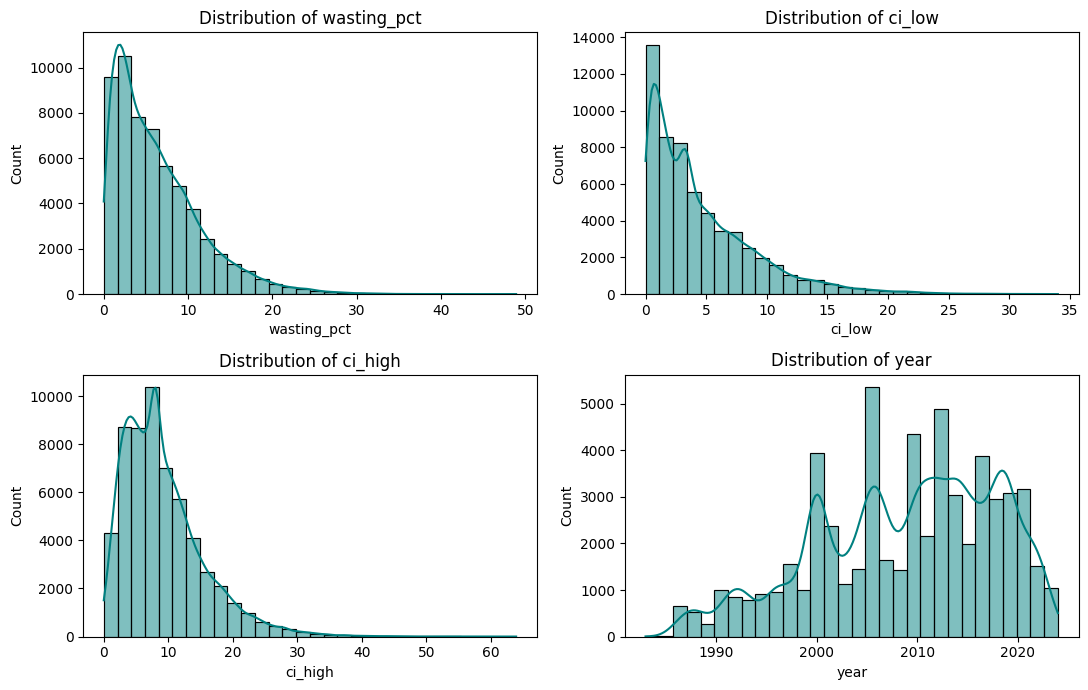

In [ ]:
num_cols = ["wasting_pct", "ci_low", "ci_high", "year"]

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], bins=30, kde=True, color="teal", ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

**Observation**


- wasting_pct, ci_low and ci_high are all right-skewed. Most values are low (wasting_pct is mostly 2% to 3% with a median of 5.1%), and a long tail stretches to the right up to 48.9%, 34% and 63.9%.
- About 80% of the records have a wasting rate of 10% or less, so very high wasting is rare.
- ci_low and ci_high show a spike at their medians (3.3% and 8.0%), because the missing values were filled with the median.
- Most records in year are from after 2000 (about 85%), with fewer from the 1980s and 1990s and a sharp drop after 2022, so the latest years have less data.

**Box plot**

A box plot is used to understand the spread and distribution of numerical variables. It helps identify the median, quartiles, and potential extreme values in the data.

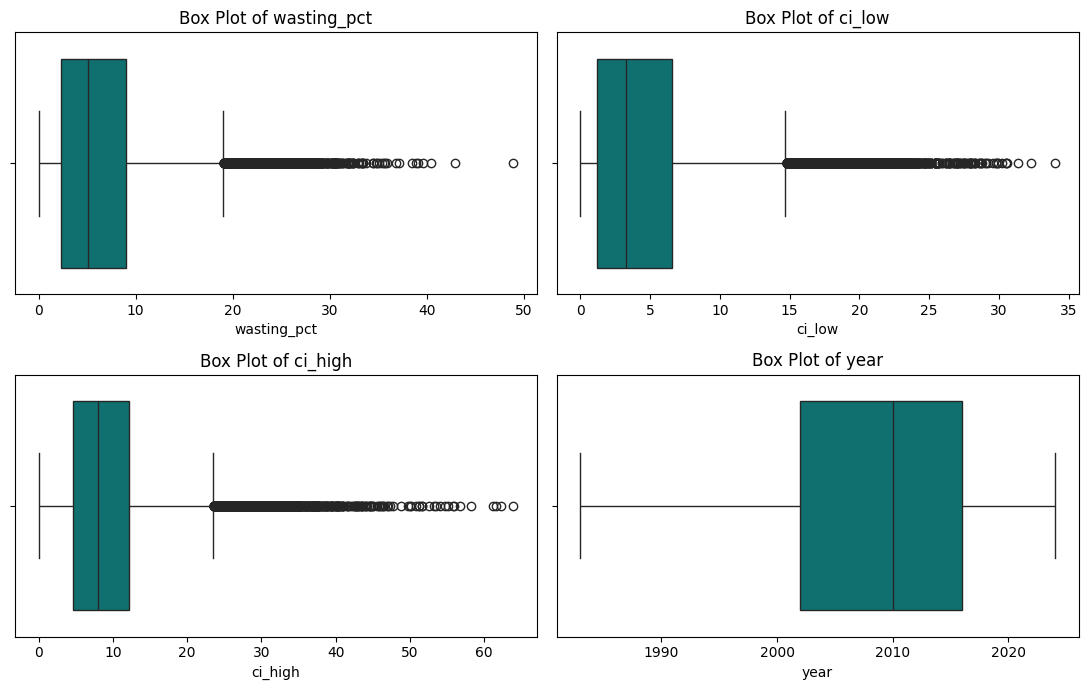

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(x=df[col], color="teal", ax=ax)
    ax.set_title(f"Box Plot of {col}")
plt.tight_layout()
plt.show()

**Observation:**
- The middle 50% of wasting rates lies between about 2.4% and 9.1%, with a median of 5.1%, and the longer right whisker confirms the right skew.
- wasting_pct, ci_low and ci_high have extreme values only on the high side (above about 19%, 15% and 24%). They are about 3% of the records and are real high-wasting cases.
- ci_high has the widest box, so it has the most spread of the three.
- year has no outliers, and its middle 50% lies between 2002 and 2016, with a median of 2010.

**6.1.2 Categorical Variables**

**Count Plot**

Categorical variables contain values that represent different groups or categories. Count plots are used to show the frequency of observations in each category. This helps to understand the distribution of categorical variables (sex, urbanity, wealth_quintile and mother_edu) in the dataset. Rows marked NOT_APPLICABLE or TOTAL are excluded, because they are not separate groups.

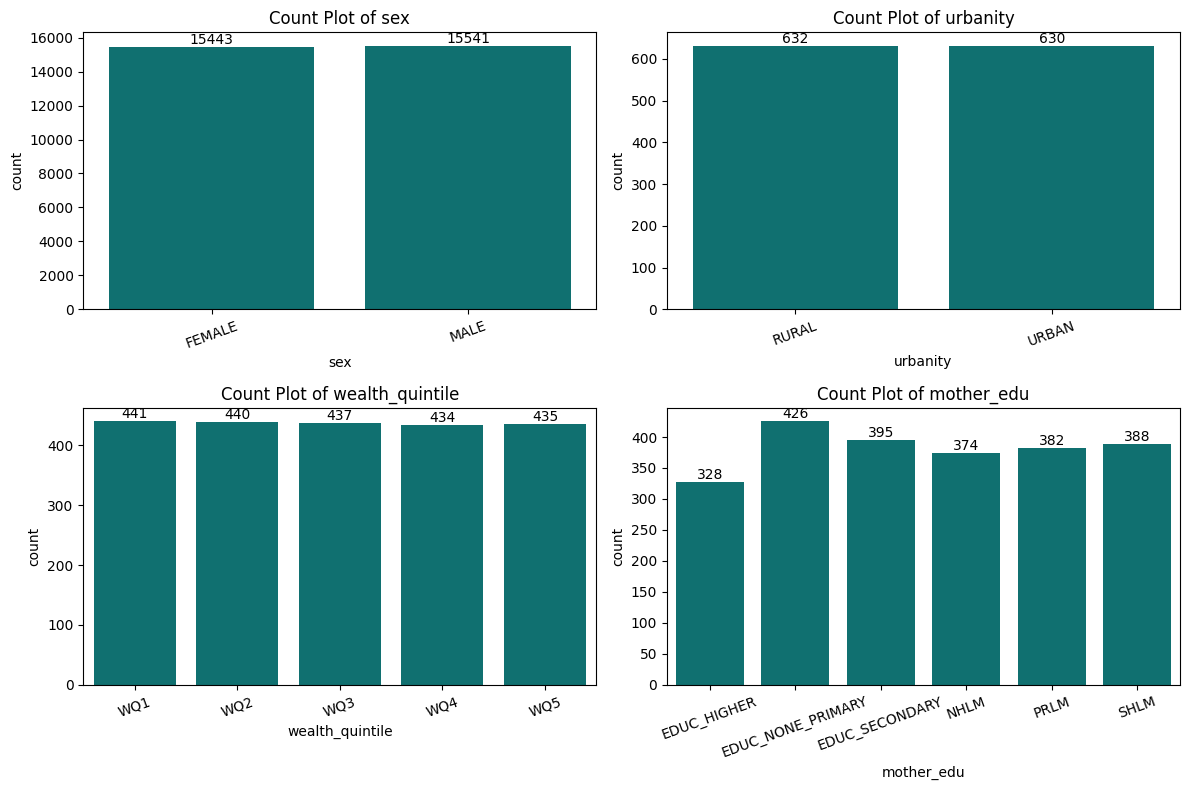

In [ ]:
cat_cols = ["sex", "urbanity", "wealth_quintile", "mother_edu"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, cat_cols):
    data = df[~df[col].isin(["NOT_APPLICABLE", "TOTAL"])]
    sns.countplot(data=data, x=col, order=sorted(data[col].unique()), color="teal", ax=ax)
    ax.bar_label(ax.containers[0])
    ax.set_title(f"Count Plot of {col}")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

**Observation**


- sex: male (15,541) and female (15,443) records are almost equal, so the sex groups are balanced.
- urbanity: urban (630) and rural (632) have nearly the same number of records.
- wealth_quintile: the five quintiles each have about 435 to 441 records, so the wealth groups are balanced.
- mother_edu: the categories are not equal. EDUC_NONE_PRIMARY has the most records (426) and EDUC_HIGHER the fewest (328). The column also mixes two coding schemes (EDUC_* and NHLM, PRLM, SHLM), so only one scheme is used in the analysis.
- The counts show how many data rows each group has, not how many children. Balanced counts mean each group has similar data coverage, so group comparisons are fair.

#### Bar Plot

A bar plot is used to compare the frequency of different categories. It provides a clear visual comparison of the most common and least common categories within a categorical variable. Here, the countries with the most records and the child age groups are compared.

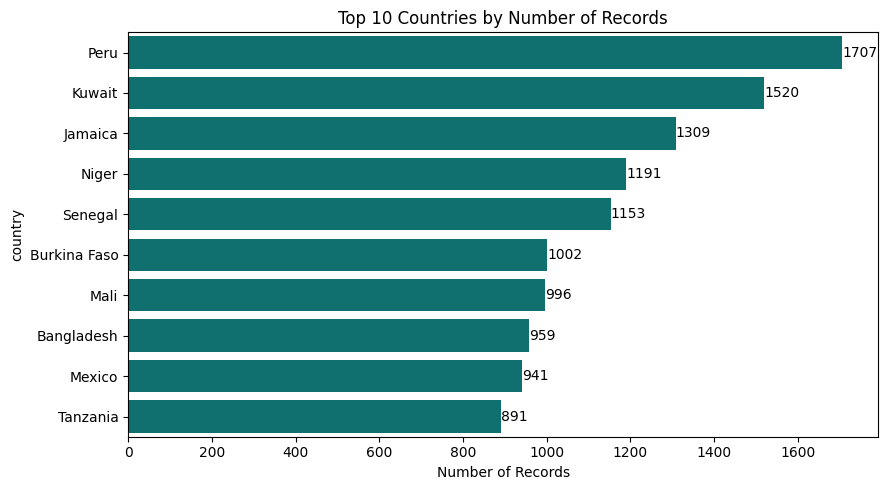

In [ ]:
#top 10 countries by number of records

top10 = df["country"].value_counts().head(10).reset_index()
top10.columns = ["country", "records"]

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=top10, y="country", x="records", color="teal")
ax.bar_label(ax.containers[0])
plt.title("Top 10 Countries by Number of Records")
plt.xlabel("Number of Records")
plt.tight_layout()
plt.show()

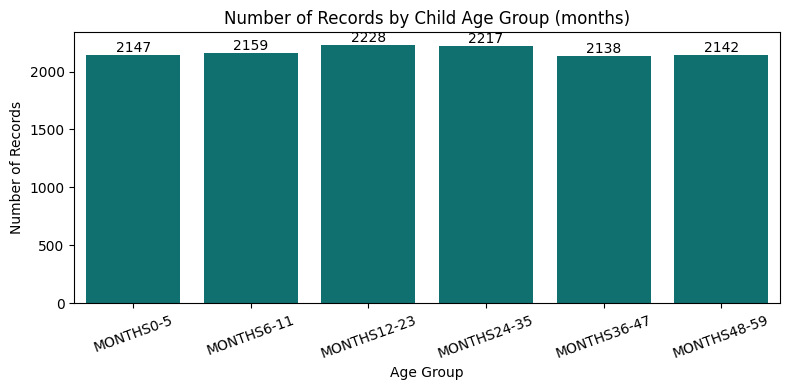

In [ ]:
#child age groups
age_order = ["MONTHS0-5", "MONTHS6-11", "MONTHS12-23", "MONTHS24-35", "MONTHS36-47", "MONTHS48-59"]
age_counts = df[df["age_group"].isin(age_order)]["age_group"].value_counts().reindex(age_order)

plt.figure(figsize=(8, 4))
ax = sns.barplot(x=age_counts.index, y=age_counts.values, color="teal")
ax.bar_label(ax.containers[0])
plt.title("Number of Records by Child Age Group (months)")
plt.xlabel("Age Group")
plt.ylabel("Number of Records")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Observation**


- Peru has the most records (1,707), followed by Kuwait (1,520), Jamaica (1,309), Niger (1,191) and Senegal (1,153).
- The top 10 countries together make up about 20% of all records, so the data is spread across many countries.
- Some countries have very few records. Malta has only 4, and Ireland, Latvia, Lithuania and Portugal have 5 each.
- The median country has about 289 records, so countries differ a lot in how much data they have.
- The six child age groups have almost the same number of records (about 2,140 to 2,230 each), so the age comparison is balanced.
- The counts show how many data rows each country or age group has, not the number of children or the severity of wasting.

## 6.2 Bivariate Analysis

**6.2.1 Numerical vs Numerical**

Scatter Plot

Bivariate analysis is used to study the relationship between two variables. A scatter plot is used to visualize the relationship between two numerical variables and helps identify patterns, trends, or possible relationships between them. Here, wasting_pct is compared with ci_low, ci_high and year.

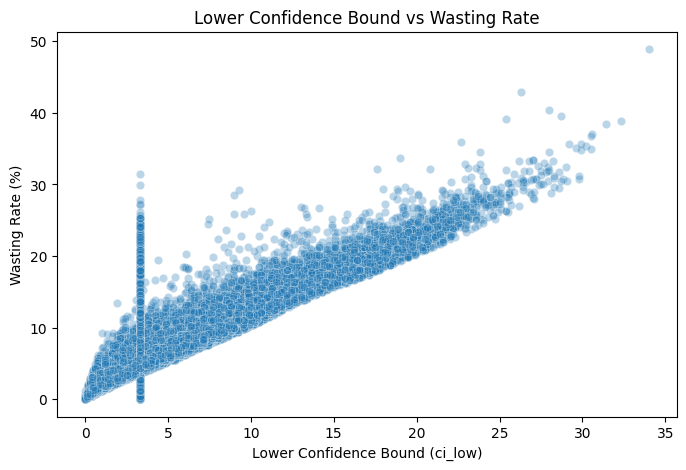

In [ ]:
# Wasting Rate vs Lower Bound

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="ci_low", y="wasting_pct", alpha=0.3)

plt.title("Lower Confidence Bound vs Wasting Rate")
plt.xlabel("Lower Confidence Bound (ci_low)")
plt.ylabel("Wasting Rate (%)")
plt.show()

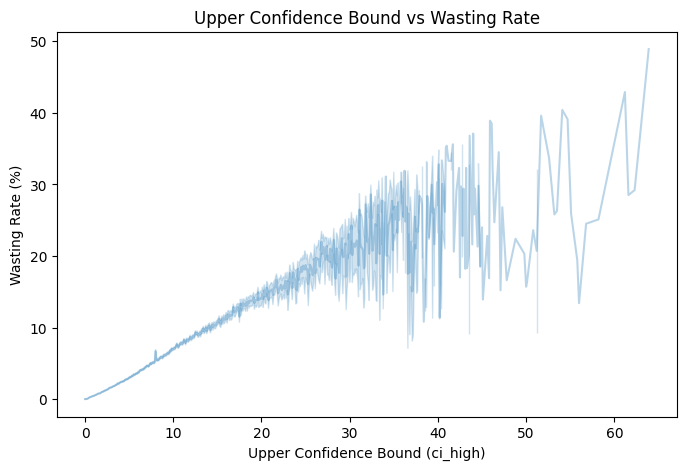

In [ ]:
# Wasting Rate vs Upper Bound

plt.figure(figsize=(8, 5))

sns.lineplot(data=df, x="ci_high", y="wasting_pct", alpha=0.3)

plt.title("Upper Confidence Bound vs Wasting Rate")
plt.xlabel("Upper Confidence Bound (ci_high)")
plt.ylabel("Wasting Rate (%)")
plt.show()

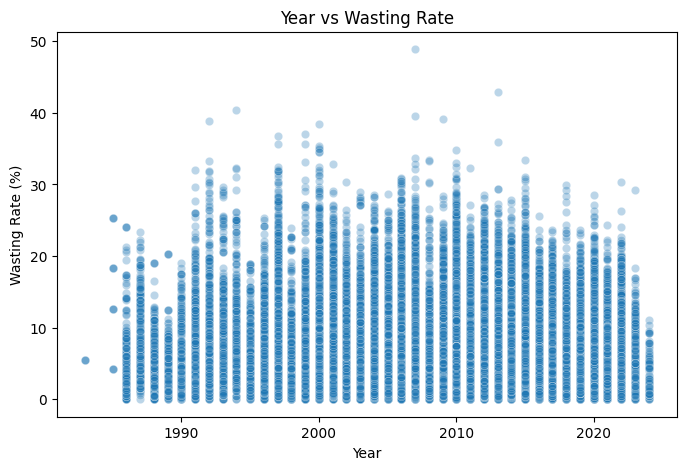

In [ ]:
# Wasting Rate vs Year

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="year", y="wasting_pct", alpha=0.3)

plt.title("Year vs Wasting Rate")
plt.xlabel("Year")
plt.ylabel("Wasting Rate (%)")
plt.show()

In [ ]:
for x in ["ci_low", "ci_high", "year"]:
    print(f"wasting_pct vs {x}:", round(df[x].corr(df["wasting_pct"]), 2))

wasting_pct vs ci_low: 0.95
wasting_pct vs ci_high: 0.88
wasting_pct vs year: -0.07


**Observationt**


- wasting_pct vs ci_low: the points form a tight upward line (correlation about 0.95), so records with a higher wasting rate also have a higher lower bound.
- wasting_pct vs ci_high: the relationship is also strongly positive (about 0.88), but the points are more spread out, because high rates have more uncertainty.
- These strong relationships are expected, because the confidence bounds are calculated around the wasting rate, so they do not show a new finding.
- wasting_pct vs year: the points form a flat cloud with almost no pattern (correlation about -0.07), so wasting does not change much with year across all countries combined.
- The highest wasting values (above 40%) occur in the years before 2020, and the highest value in the data (48.9%) is from 2007.

### 6.2.2 Categorical vs Numerical

Box plots and bar plots are used to compare the wasting rate (wasting_pct) across wealth quintile, mother's education, urban/rural areas and child age group.

In [ ]:
breakdown_cols = ["sex", "urbanity", "wealth_group", "wealth_quintile",
                  "wealth_decile", "wealth_tercile", "mother_edu", "age_group"]

def only(dim):
    m = ~df[dim].isin(["NOT_APPLICABLE", "TOTAL"])
    for c in breakdown_cols:
        if c != dim:
            ok = ["NOT_APPLICABLE", "TOTAL"] if c in ("sex", "age_group") else ["NOT_APPLICABLE"]
            m &= df[c].isin(ok)
    return df[m]

wealth = only("wealth_quintile")
wealth = wealth[wealth["wealth_quintile"].isin(["WQ1", "WQ2", "WQ3", "WQ4", "WQ5"])]

edu = only("mother_edu")
edu = edu[edu["mother_edu"].isin(["EDUC_NONE_PRIMARY", "EDUC_SECONDARY", "EDUC_HIGHER"])]

urban = only("urbanity")
urban = urban[urban["urbanity"].isin(["URBAN", "RURAL"])]

age_order = ["MONTHS0-5", "MONTHS6-11", "MONTHS12-23", "MONTHS24-35", "MONTHS36-47", "MONTHS48-59"]
age = only("age_group")
age = age[age["age_group"].isin(age_order)]

### Box plot

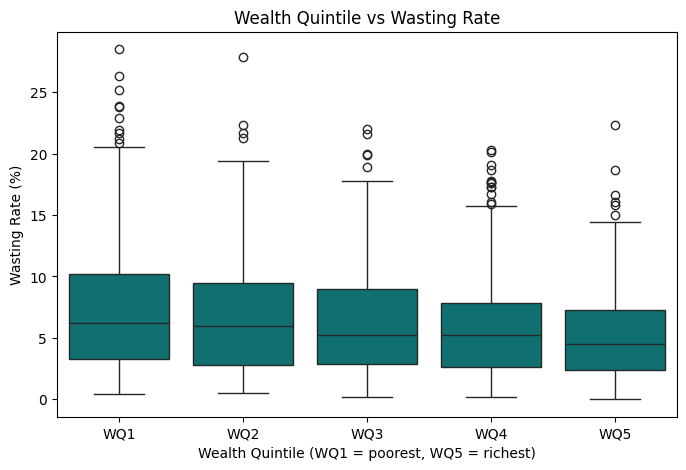

In [ ]:
# Wealth Quintile vs Wasting Rate

plt.figure(figsize=(8, 5))
sns.boxplot(data=wealth, x="wealth_quintile", y="wasting_pct",
            order=["WQ1", "WQ2", "WQ3", "WQ4", "WQ5"], color="teal")
plt.title("Wealth Quintile vs Wasting Rate")
plt.xlabel("Wealth Quintile (WQ1 = poorest, WQ5 = richest)")
plt.ylabel("Wasting Rate (%)")
plt.show()

### Bar plot

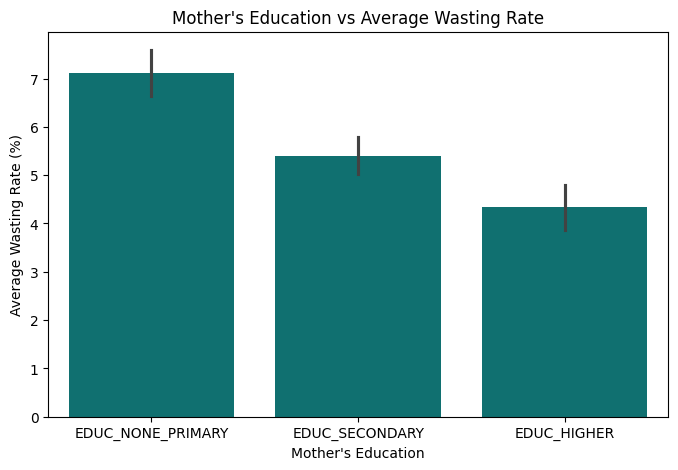

In [ ]:
# Mother’s Education vs Wasting Rate

plt.figure(figsize=(8, 5))
sns.barplot(data=edu, x="mother_edu", y="wasting_pct",
            order=["EDUC_NONE_PRIMARY", "EDUC_SECONDARY", "EDUC_HIGHER"], color="teal")
plt.title("Mother's Education vs Average Wasting Rate")
plt.xlabel("Mother's Education")
plt.ylabel("Average Wasting Rate (%)")
plt.show()

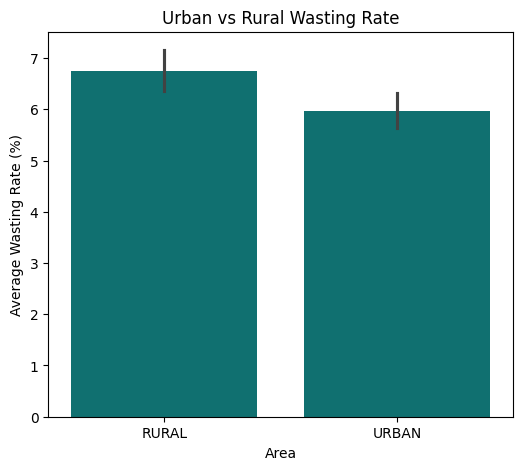

In [ ]:
# Urban vs Rural

plt.figure(figsize=(6, 5))
sns.barplot(data=urban, x="urbanity", y="wasting_pct", color="teal")
plt.title("Urban vs Rural Wasting Rate")
plt.xlabel("Area")
plt.ylabel("Average Wasting Rate (%)")
plt.show()

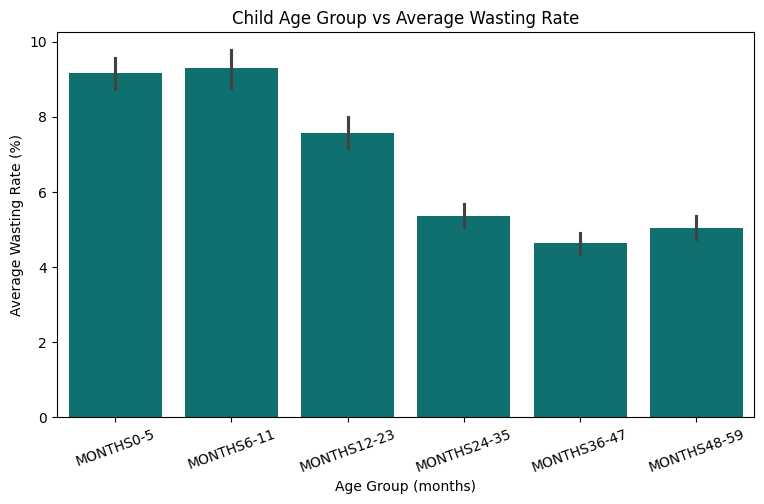

In [ ]:
# Child Age Group vs Wasting Rate

plt.figure(figsize=(9, 5))
sns.barplot(data=age, x="age_group", y="wasting_pct", order=age_order, color="teal")
plt.title("Child Age Group vs Average Wasting Rate")
plt.xlabel("Age Group (months)")
plt.ylabel("Average Wasting Rate (%)")
plt.xticks(rotation=20)
plt.show()

In [ ]:
# average values

print(wealth.groupby("wealth_quintile")["wasting_pct"].mean().round(2), "\n")
print(edu.groupby("mother_edu")["wasting_pct"].mean().round(2), "\n")
print(urban.groupby("urbanity")["wasting_pct"].mean().round(2), "\n")
print(age.groupby("age_group")["wasting_pct"].mean().reindex(age_order).round(2))

wealth_quintile
WQ1    7.41
WQ2    6.76
WQ3    6.29
WQ4    5.92
WQ5    5.17
Name: wasting_pct, dtype: float64 

mother_edu
EDUC_HIGHER          4.33
EDUC_NONE_PRIMARY    7.11
EDUC_SECONDARY       5.39
Name: wasting_pct, dtype: float64 

urbanity
RURAL    6.75
URBAN    5.97
Name: wasting_pct, dtype: float64 

age_group
MONTHS0-5      9.15
MONTHS6-11     9.29
MONTHS12-23    7.57
MONTHS24-35    5.36
MONTHS36-47    4.63
MONTHS48-59    5.04
Name: wasting_pct, dtype: float64


**Observation**


- Wealth: wasting falls steadily from about 7.5% in the poorest quintile (WQ1) to about 5.2% in the richest (WQ5).
- Mother's education: wasting is about 7.2% with no or primary education, 5.4% with secondary and 4.4% with higher education.
- Urban vs rural: rural children (6.8%) have a slightly higher wasting rate than urban children (6.0%), but the gap is small.
- Age: wasting is highest in the first year of life (about 9.2% to 9.3% at 0 to 11 months) and falls to about 4.7% at 36 to 47 months.
- Wealth and mother's education show the clearest differences, and the first year of life is the most vulnerable age.

##6.2.3 Categorical vs Categorical
Count Plot + Cross Tabulation

Categorical vs categorical analysis is used to study the relationship between two categorical variables. A count plot helps visualize the frequency of combinations of categories, while a cross-tabulation shows the corresponding counts in tabular form.

Here, the wasting rate (wasting_pct) is grouped into three levels (Low, Medium, High) and compared with wealth quintile, mother's education and urban/rural areas.


In [ ]:
# create the wasting level

all_rows = pd.concat([wealth, edu, urban])
low, high = all_rows["wasting_pct"].quantile([0.33, 0.67])

def level(x):
    if x <= low:
        return "Low"
    elif x > high:
        return "High"
    return "Medium"

level_order = ["Low", "Medium", "High"]

wealth = wealth.copy()
edu = edu.copy()
urban = urban.copy()

for t in (wealth, edu, urban):
    t["wasting_level"] = t["wasting_pct"].apply(level)

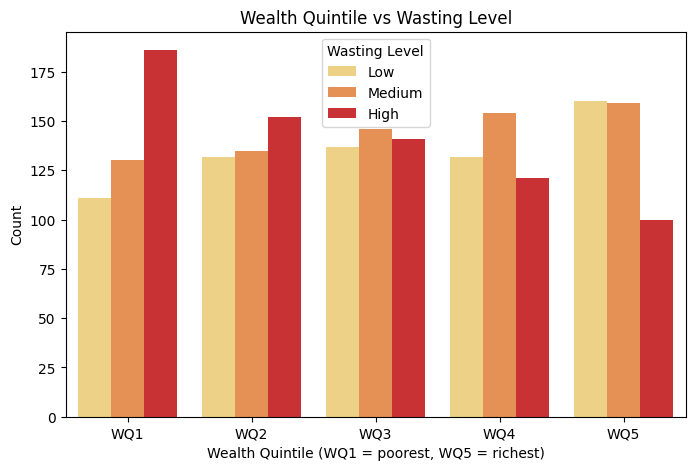

wasting_level    Low  Medium  High   All
wealth_quintile                         
WQ1              111     130   186   427
WQ2              132     135   152   419
WQ3              137     146   141   424
WQ4              132     154   121   407
WQ5              160     159   100   419
All              672     724   700  2096
wasting_level     Low  Medium  High
wealth_quintile                    
WQ1              26.0    30.4  43.6
WQ2              31.5    32.2  36.3
WQ3              32.3    34.4  33.3
WQ4              32.4    37.8  29.7
WQ5              38.2    37.9  23.9


In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(
    data=wealth,
    x="wealth_quintile",
    hue="wasting_level",
    order=["WQ1","WQ2","WQ3","WQ4","WQ5"],
    hue_order=level_order,
    palette="YlOrRd"
)
plt.title("Wealth Quintile vs Wasting Level")
plt.xlabel("Wealth Quintile (WQ1 = poorest, WQ5 = richest)")
plt.ylabel("Count")
plt.legend(title="Wasting Level")
plt.show()

# Crosstab summaries
ct_counts = pd.crosstab(wealth["wealth_quintile"], wealth["wasting_level"], margins=True)
ct_perc = pd.crosstab(wealth["wealth_quintile"], wealth["wasting_level"], normalize="index").mul(100).round(1)

print(ct_counts.reindex(columns=level_order+["All"]))
print(ct_perc.reindex(columns=level_order))


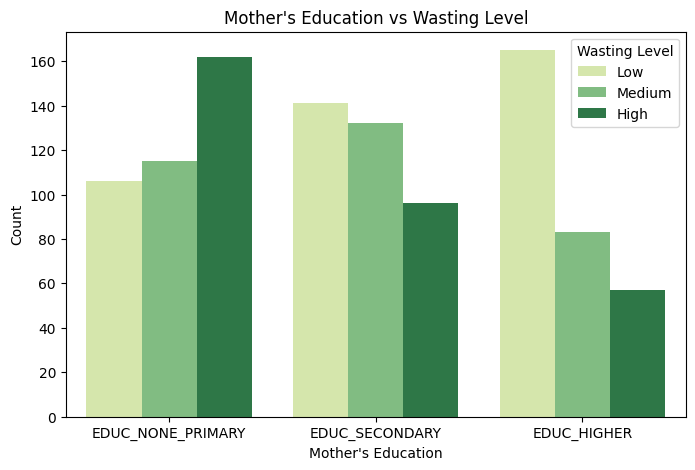

wasting_level      Low  Medium  High   All
mother_edu                                
EDUC_HIGHER        165      83    57   305
EDUC_NONE_PRIMARY  106     115   162   383
EDUC_SECONDARY     141     132    96   369
All                412     330   315  1057

wasting_level       Low  Medium  High
mother_edu                           
EDUC_HIGHER        54.1    27.2  18.7
EDUC_NONE_PRIMARY  27.7    30.0  42.3
EDUC_SECONDARY     38.2    35.8  26.0


In [ ]:
# Mother’s Education vs Wasting Level

edu_order = ["EDUC_NONE_PRIMARY", "EDUC_SECONDARY", "EDUC_HIGHER"]

plt.figure(figsize=(8, 5))
sns.countplot(data=edu, x="mother_edu", hue="wasting_level",
              order=edu_order, hue_order=level_order, palette="YlGn")
plt.title("Mother's Education vs Wasting Level")
plt.xlabel("Mother's Education")
plt.ylabel("Count")
plt.legend(title="Wasting Level")
plt.show()

print(pd.crosstab(edu["mother_edu"], edu["wasting_level"],
                  margins=True).reindex(columns=level_order + ["All"]))
print()
print(pd.crosstab(edu["mother_edu"], edu["wasting_level"],
                  normalize="index").reindex(columns=level_order).mul(100).round(1))

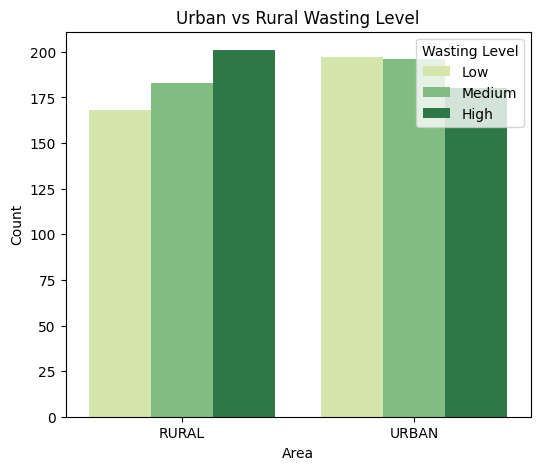

wasting_level  Low  Medium  High   All
urbanity                              
RURAL          168     183   201   552
URBAN          197     196   180   573
All            365     379   381  1125

wasting_level   Low  Medium  High
urbanity                         
RURAL          30.4    33.2  36.4
URBAN          34.4    34.2  31.4


In [ ]:
# Urban vs Rural vs Wasting Level

plt.figure(figsize=(6, 5))
sns.countplot(data=urban, x="urbanity", hue="wasting_level",
              hue_order=level_order, palette="YlGn")
plt.title("Urban vs Rural Wasting Level")
plt.xlabel("Area")
plt.ylabel("Count")
plt.legend(title="Wasting Level")
plt.show()

print(pd.crosstab(urban["urbanity"], urban["wasting_level"],
                  margins=True).reindex(columns=level_order + ["All"]))
print()
print(pd.crosstab(urban["urbanity"], urban["wasting_level"],
                  normalize="index").reindex(columns=level_order).mul(100).round(1))

**Observation**



- Wealth: the share of High wasting is largest in the poorest quintiles (WQ1, WQ2) and smallest in WQ5.
- Mother's education: High wasting is most common when the mother has no or only primary education and least common with higher education.
- Urban vs rural: rural areas have a somewhat larger share of High wasting than urban areas, but the difference is small.
- The row-percentage tables are more reliable than the raw counts for comparing groups, because the groups may have different numbers of rows.

##6.3 Multivariate Analysis

Multivariate analysis is used to study relationships among more than two variables at the same time. It helps to understand how multiple numerical and categorical variables are related and provides deeper insights into patterns within the dataset.

Here, a correlation heatmap and a pair plot are used for the numerical variables, and a grouped bar plot and a heatmap are used to look at wasting rate (wasting_pct) across two categorical variables together (child age group and sex).


### 6.3.1 Correlation Heatmap

A correlation heatmap is used to visualize the correlation between numerical variables. It helps identify the strength and direction of relationships between the variables.

Here, the correlation between all numerical columns of the dataset is shown as a heatmap, and the strongest pairs of variables are listed.

In [ ]:
num_cols = df.select_dtypes(include="number").columns.tolist()
print("Numerical columns:", num_cols)

Numerical columns: ['year', 'country_code', 'wasting_pct', 'ci_low', 'ci_high']


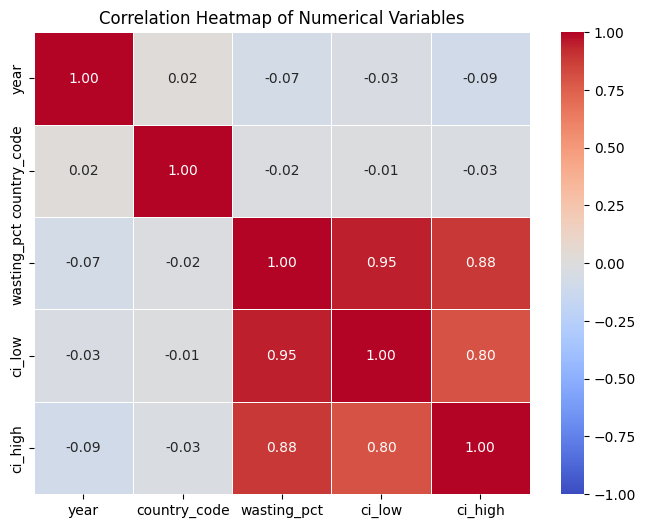

In [ ]:
corr = df[num_cols].corr()


plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

Observation:

The correlation heatmap was used to identify the strength and direction of linear relationships between the numerical variables in the dataset.

The highest positive correlation was between 'wasting_pct' and 'ci_low' (approximately 0.95), followed by 'wasting_pct' and 'ci_high' (approximately 0.88). These strong relationships are expected, because the confidence bounds are calculated around the wasting rate.

The correlation between 'year' and 'wasting_pct' was approximately -0.07, showing a very weak negative relationship. Overall, the wasting rate and its confidence bounds are strongly related, while year has almost no linear relationship with them. Correlation does not imply causation.

### 6.3.2 Grouped Visualization

Grouped visualizations compare a numerical variable across two categorical variables at the same time. Here, the average wasting rate (wasting_pct) is compared by child age group and sex, by wealth quintile and time period, and by urban/rural area and time period.

In [ ]:
age_order = ["MONTHS0-5", "MONTHS6-11", "MONTHS12-23", "MONTHS24-35", "MONTHS36-47", "MONTHS48-59"]
period_order = ["1983-1999", "2000-2009", "2010-2019", "2020-2024"]

# Age group and sex together (only these two breakdowns reported)
age_sex = df[df["sex"].isin(["MALE", "FEMALE"]) & df["age_group"].isin(age_order)]
for c in ["urbanity", "wealth_group", "wealth_quintile", "wealth_decile", "wealth_tercile", "mother_edu"]:
    age_sex = age_sex[age_sex[c] == "NOT_APPLICABLE"]

# Time periods
def add_period(d):
    d = d.copy()
    d["period"] = pd.cut(d["year"], [1982, 1999, 2009, 2019, 2024], labels=period_order)
    return d

wealth_p = add_period(wealth)
urban_p = add_period(urban)

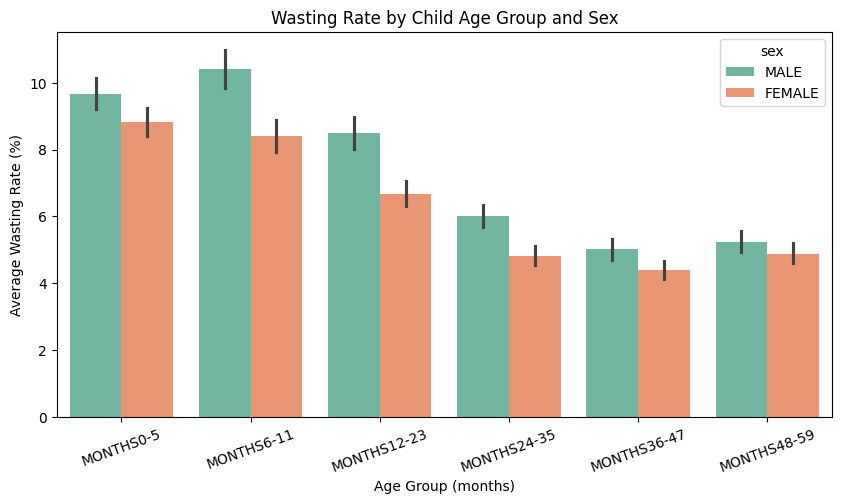

In [ ]:
# Age Group by Sex

plt.figure(figsize=(10, 5))
sns.barplot(data=age_sex, x="age_group", y="wasting_pct", hue="sex",
            order=age_order, hue_order=["MALE", "FEMALE"], palette="Set2")

plt.title("Wasting Rate by Child Age Group and Sex")
plt.xlabel("Age Group (months)")
plt.ylabel("Average Wasting Rate (%)")
plt.xticks(rotation=20)
plt.show()

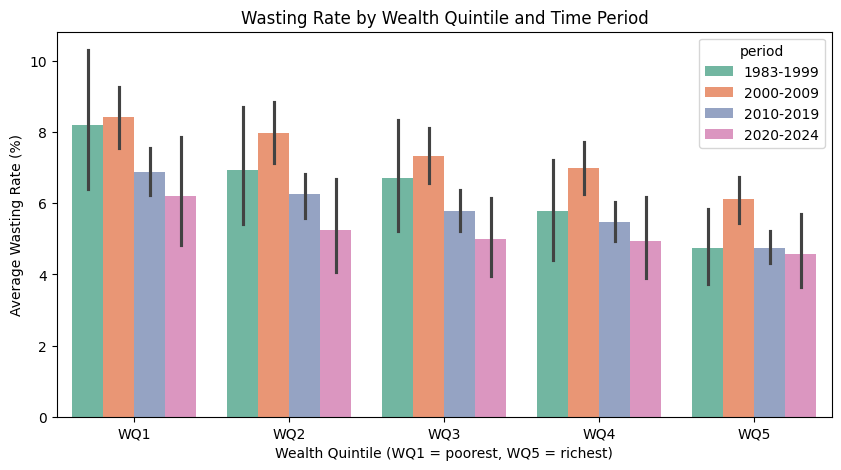

In [ ]:
# Wealth Quintile by Period

plt.figure(figsize=(10, 5))
sns.barplot(data=wealth_p, x="wealth_quintile", y="wasting_pct", hue="period",
            order=["WQ1", "WQ2", "WQ3", "WQ4", "WQ5"], hue_order=period_order, palette="Set2")
plt.title("Wasting Rate by Wealth Quintile and Time Period")
plt.xlabel("Wealth Quintile (WQ1 = poorest, WQ5 = richest)")
plt.ylabel("Average Wasting Rate (%)")
plt.show()

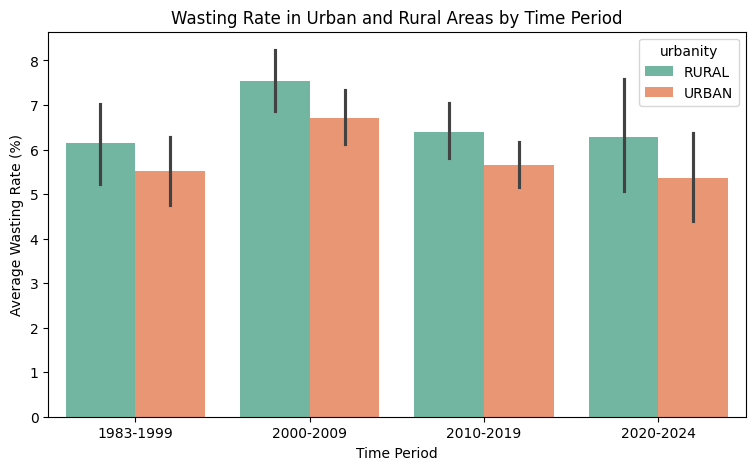

In [ ]:
# Urban vs Rural by Period

plt.figure(figsize=(9, 5))
sns.barplot(data=urban_p, x="period", y="wasting_pct", hue="urbanity",
            order=period_order, hue_order=["RURAL", "URBAN"], palette="Set2")
plt.title("Wasting Rate in Urban and Rural Areas by Time Period")
plt.xlabel("Time Period")
plt.ylabel("Average Wasting Rate (%)")
plt.show()

### Observation
- Age and sex: boys have a higher wasting rate than girls in every age group. The gap is largest at 6 to 11 months (about 10.5% for boys and 8.4% for girls). Wasting is highest in the first year of life for both sexes and falls to about 4.4% to 5.3% after 3 years.
- Wealth and period: the poorest quintile (WQ1) has the highest wasting in every period, and the richest (WQ5) the lowest. The gap between them narrowed from about 3.5 percentage points in 1983-1999 to about 1.7 in 2020-2024, mainly because wasting fell in the poorest group (from about 8.2% to 6.3%) while the richest group stayed near 4.6% to 4.8%.
- Urban vs rural: rural areas have a higher wasting rate than urban areas in all four periods, by about 0.6 to 0.9 percentage points.
- In all three charts the pattern is consistent: younger children, boys, poorer households and rural areas have higher wasting.

### 6.3.3 Pair Plot

A pair plot is used to visualize the relationships between multiple numerical variables. It shows the distribution of each variable and the relationships between pairs of variables. This helps identify patterns, trends, and possible relationships in the dataset.

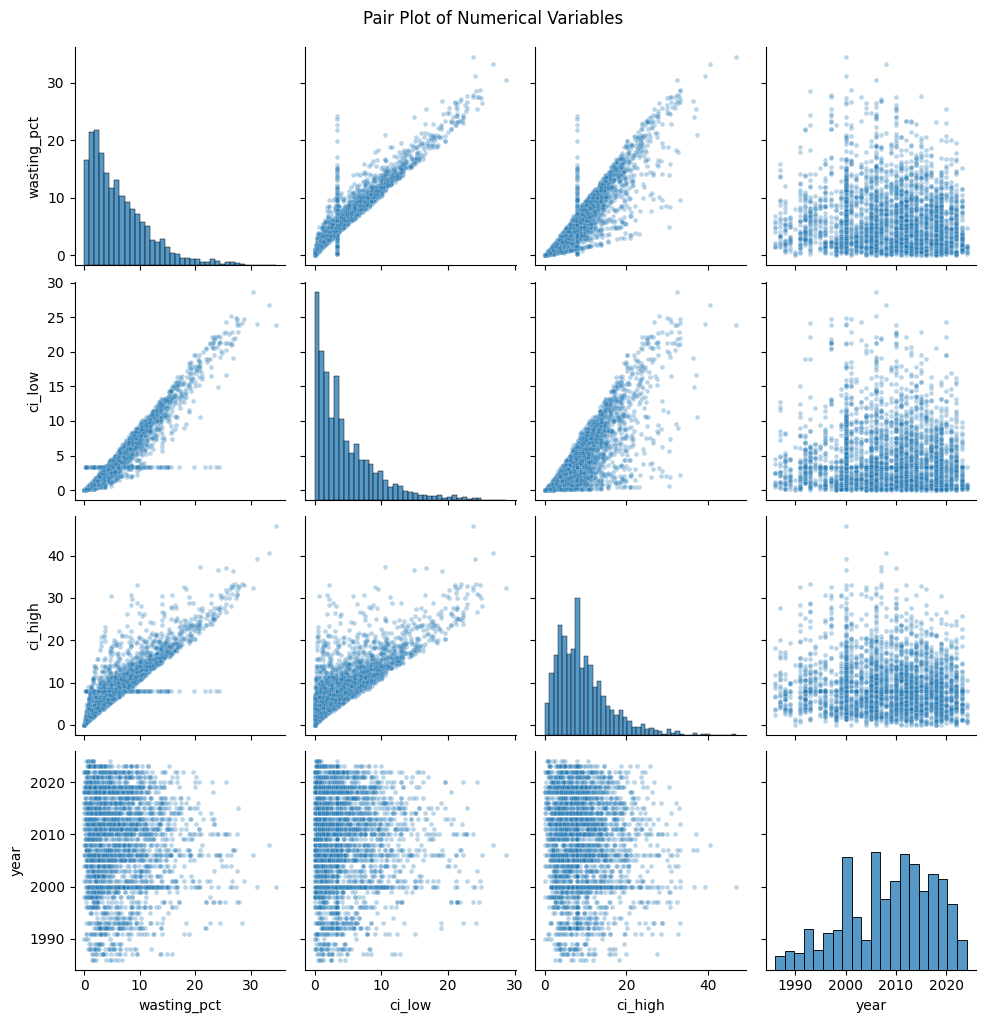

In [ ]:
num_cols = ["wasting_pct", "ci_low", "ci_high", "year"]
sample = df[num_cols].sample(3000, random_state=42)

g = sns.pairplot(sample, diag_kind="hist", plot_kws={"alpha": 0.3, "s": 12})
g.fig.suptitle("Pair Plot of Numerical Variables", y=1.02)
plt.show()

###  Observation
- The diagonal histograms show that wasting_pct, ci_low and ci_high are right-skewed, with most values low and a few very high ones.
- wasting_pct vs ci_low and wasting_pct vs ci_high form tight upward lines (correlations of about 0.95 and 0.88), because the confidence bounds are calculated around the wasting rate.
- ci_low vs ci_high also shows a positive relationship (about 0.80).
- The year panels show a flat cloud with almost no pattern (correlation of about -0.07 with wasting_pct), so there is no clear linear change with year.
- The very high wasting values (above 30%) are rare and appear as a few isolated points at the top of the plots.

###  6.4 Statistical Analysis

### 6.4.1 Mean, Median, Mode and Standard Deviation

Descriptive statistics are used to summarize the central tendency and spread of the numerical variables. The mean, median and mode describe the typical value, and the standard deviation shows how much the values vary around the mean.


In [ ]:
num_cols = ["wasting_pct", "ci_low", "ci_high", "year"]

stats_table = pd.DataFrame({
    "Mean": df[num_cols].mean(),
    "Median": df[num_cols].median(),
    "Mode": [df[col].mode()[0] for col in num_cols],
    "Std Dev": df[num_cols].std()
}).round(2)

stats_table

,Mean,Median,Mode,Std Dev
wasting_pct,6.34,5.1,1.9,5.16
ci_low,4.57,3.3,3.3,4.36
ci_high,9.22,8.0,8.0,6.28
year,2008.77,2010.0,2000.0,8.90


### Observation

- wasting_pct has a mean of 6.34%, a median of 5.1% and a mode of 1.9%. The mean is higher than the median, so a few very high rates pull the average up.
- The standard deviation of 5.16 is large compared with the mean, so wasting rates vary a lot across countries and groups.
- ci_low and ci_high show the same pattern. Their modes equal their medians because the missing values were filled with the median.
- year has a mean of 2008.8 and a median of 2010, so most records are from recent years.

### 6.4.2 Correlation Analysis

Correlation analysis is used to measure the strength and direction of the linear relationship between the numerical variables. The correlation coefficient ranges from -1 to +1. A value close to +1 shows a strong positive relationship, a value close to -1 shows a strong negative relationship, and a value close to 0 shows little or no linear relationship.

In [ ]:
num_cols = ["wasting_pct", "ci_low", "ci_high", "year"]
corr = df[num_cols].corr().round(2)
corr

,wasting_pct,ci_low,ci_high,year
wasting_pct,1.00,0.95,0.88,-0.07
ci_low,0.95,1.00,0.80,-0.03
ci_high,0.88,0.80,1.00,-0.09
year,-0.07,-0.03,-0.09,1.00


### Observation


- wasting_pct has a very strong positive correlation with ci_low (0.95) and a strong one with ci_high (0.88). This is expected, because the confidence bounds are calculated around the wasting rate.
- ci_low and ci_high are also strongly correlated (0.80).
- year has very weak negative correlations with all other variables (-0.03 to -0.09), so there is almost no linear change in wasting with year across all countries combined.
- Correlation does not imply causation.

### 6.4.3  Percentage Analysis



Percentage analysis is used to express counts as shares of the whole, which makes groups easier to compare. Here, the percentage of records in each category is calculated, and the wasting rate is grouped into severity levels based on commonly used prevalence thresholds (very low below 2.5%, low 2.5% to below 5%, medium 5% to below 10%, high 10% to below 15%, and very high 15% or more).

In [ ]:
for col in ["sex", "urbanity", "wealth_quintile"]:
    data = df[~df[col].isin(["NOT_APPLICABLE", "TOTAL"])]
    print((data[col].value_counts(normalize=True) * 100).round(1).sort_index(), "\n")

sex
FEMALE    49.8
MALE      50.2
Name: proportion, dtype: float64 

urbanity
RURAL    50.1
URBAN    49.9
Name: proportion, dtype: float64 

wealth_quintile
WQ1    20.2
WQ2    20.1
WQ3    20.0
WQ4    19.8
WQ5    19.9
Name: proportion, dtype: float64 



In [ ]:
# wasting severity level (national records)

overall = df[df[breakdown_cols].isin(["NOT_APPLICABLE", "TOTAL"]).all(axis=1)]
overall = overall.drop_duplicates(subset=["country", "year", "wasting_pct"]).copy()

labels = ["Very low (<2.5%)", "Low (2.5-<5%)", "Medium (5-<10%)", "High (10-<15%)", "Very high (>=15%)"]
overall["wasting_level"] = pd.cut(overall["wasting_pct"], bins=[0, 2.5, 5, 10, 15, 100],
                                  labels=labels, right=False, include_lowest=True)

print((overall["wasting_level"].value_counts(normalize=True).reindex(labels) * 100).round(1))

wasting_level
Very low (<2.5%)     24.8
Low (2.5-<5%)        23.6
Medium (5-<10%)      30.7
High (10-<15%)       14.3
Very high (>=15%)     6.6
Name: proportion, dtype: float64


In [ ]:
# latest survey per country

latest = overall.sort_values("year").groupby("country").tail(1).copy()
latest["wasting_level"] = pd.cut(latest["wasting_pct"], bins=[0, 2.5, 5, 10, 15, 100],
                                 labels=labels, right=False, include_lowest=True)

print((latest["wasting_level"].value_counts(normalize=True).reindex(labels) * 100).round(1))
print("Records with wasting >= 10%:", round((df["wasting_pct"] >= 10).mean() * 100, 1), "%")

wasting_level
Very low (<2.5%)     33.5
Low (2.5-<5%)        29.9
Medium (5-<10%)      26.2
High (10-<15%)        7.3
Very high (>=15%)     3.0
Name: proportion, dtype: float64
Records with wasting >= 10%: 20.4 %


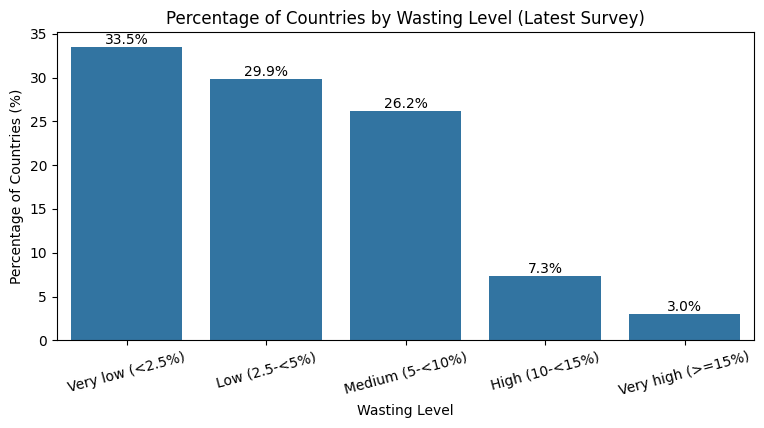

In [ ]:
pct = (latest["wasting_level"].value_counts(normalize=True).reindex(labels) * 100).round(1)

plt.figure(figsize=(9, 4))
ax = sns.barplot(x=pct.index, y=pct.values)
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.title("Percentage of Countries by Wasting Level (Latest Survey)")
plt.xlabel("Wasting Level")
plt.ylabel("Percentage of Countries (%)")
plt.xticks(rotation=15)
plt.show()

### Observations:
- The sex, urbanity and wealth quintile groups are almost perfectly balanced in the data (about 50% each for sex and urban/rural, and about 20% for each wealth quintile).
- Among national records, about 31% fall in the medium wasting level, and about 21% are at the high or very high level (10% or more).
- Using each country's latest survey, about 63% of countries have low or very low wasting, while about 10% have high or very high wasting, and 3% are at the very high level (15% or more).
- About 20% of all records have a wasting rate of 10% or more, so high wasting is a serious problem in a smaller group of countries and populations.

## 6.5 Data Visualization

## Plotly Pie Chart
A Plotly pie chart shows how a whole is divided into parts, with each slice representing a category's share of the total. In this project, Plotly pie charts are used to display the proportion of countries in each wasting severity level and the distribution of records by sex. The interactive features allow users to hover over slices to view detailed values and percentages.

In [ ]:
colors = ["#2a9d8f", "#8ab17d", "#e9c46a", "#f4a261", "#e76f51"]
counts = latest["wasting_level"].value_counts().reindex(labels)

fig = px.pie(
    values=counts.values,
    names=labels,
    color=labels,
    color_discrete_sequence=colors,
    title="Countries by Wasting Level (Latest Survey)"
)

fig.update_traces(
    textinfo="percent",
    textposition="inside",
    insidetextorientation="auto",
    sort=False
)

fig.update_layout(
    legend_title_text="Wasting Level"
)

fig.show()

In [ ]:
import plotly.express as px

# Safely detect the gender column name
sex_col = "sex" if "sex" in df.columns else "DIM_SEX"

# records by sex
sex_counts = df[df[sex_col].isin(["MALE", "FEMALE"])][sex_col].value_counts().reset_index()
sex_counts.columns = ["sex", "count"]

# Create an interactive Plotly pie chart
fig = px.pie(
    sex_counts,
    values="count",
    names="sex",
    title="Share of Records by Sex",
    color="sex",
    color_discrete_map={"MALE": "#4c78a8", "FEMALE": "#f58518"}
)

fig.update_traces(
    textinfo="percent+label",
    textposition="inside"
)

fig.show()

The pie chart shows the percentage distribution of countries across the five wasting severity levels, based on each country's latest survey. About 33.5% of countries (55) have very low wasting and 29.9% (49) have low wasting, so about 63.4% of countries have a wasting rate below 5%. Another 26.2% (43) belong to the medium level, while only 7.3% (12) have high wasting and 3.0% (5) have very high wasting. This indicates that the majority of countries have low wasting, whereas a smaller proportion of countries face high or very high wasting. The chart clearly shows that the largest share of countries falls in the very low wasting level, and that the very high level is the smallest group.

## 6.6 Final Insights and Summary

The WHO child wasting dataset was analyzed to understand the relationship between wasting among children under 5 and wealth, mother's education, age, sex, residence and time across 164 countries. Data cleaning and preprocessing were performed before conducting exploratory data analysis, visualization, and statistical analysis.

The analysis revealed the following key insights:

1. Wasting Distribution: The average wasting rate is 6.34% and the median is 5.1%, with rates ranging from 0% to 48.9%. The mean is higher than the median, which shows that the data is right-skewed, because a few countries and groups have very high wasting rates.

2. Severity Levels: Using each country's latest survey, about 63% of countries have low or very low wasting (below 5%), 26% have medium wasting, and about 10% have high or very high wasting. About 3% of countries are at the very high level (15% or more).

3. Household Wealth: The analysis showed that wasting falls steadily from about 7.5% in the poorest wealth quintile to about 5.2% in the richest. This suggests an association between poverty and higher wasting in the dataset.

4. Mother's Education: Wasting is about 7.2% when the mother has no or only primary education, 5.4% with secondary education, and 4.4% with higher education. This suggests an association between higher maternal education and lower child wasting.

5. Age and Sex: The grouped bar plot showed that wasting is highest in the first year of life (about 9% to 10% at 0 to 11 months) and falls to about 5% after 3 years. Boys (6.9%) have a higher average wasting rate than girls (5.7%), and the gap is largest at 6 to 11 months.

6. Urban vs Rural: Rural children (6.8%) have a slightly higher average wasting rate than urban children (6.0%), and rural areas are higher in every time period, but the gap is small.

7. Trend and Correlation Analysis: The average national wasting rate fell from about 7.5% in 2000 to about 5.2% in 2024, but the correlation between year and wasting was very weak (approximately -0.07). Wasting had strong correlations with the confidence bounds ci_low (0.95) and ci_high (0.88), which is expected because the bounds are calculated around the wasting rate.

8. Data Quality: Missing values, duplicate records, invalid values, inconsistent values, and potential outliers were examined during preprocessing. The breakdown columns were empty by design and were marked as NOT_APPLICABLE, the confidence bounds were filled with the median, and no duplicates or invalid values were found. Potential outliers (1,603 in wasting_pct) were retained for further analysis because they are all high values that represent real cases of high wasting.

Limitations: The averages are unweighted, survey years and countries differ across time periods, and the relationships found are associations that do not prove causation.

##Conclusion:
This project demonstrated the use of Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn for data cleaning, exploratory data analysis, statistical analysis, and visualization. The findings show patterns associated with child wasting, such as household wealth, mother's education, and the child's age, but they do not establish that any single factor directly causes higher or lower wasting.